# 03. Huấn Luyện Extra Trees (`extra_trees.joblib`)
Mô hình **Extremely Randomized Trees (ExtraTreesClassifier)** chia ngưỡng ngẫu nhiên giúp giảm phương sai khi dữ liệu khai báo từ người bệnh có nhiễu. Artifact xuất ra `/notebook/model/extra_trees.joblib`.

In [1]:
import sys
from pathlib import Path
ROOT = Path.cwd().resolve().parent if Path.cwd().name == "notebook" else Path.cwd().resolve()
sys.path.insert(0, str(ROOT))

import joblib
import pandas as pd
from sklearn.ensemble import ExtraTreesClassifier
from sklearn.impute import SimpleImputer
from sklearn.metrics import average_precision_score, brier_score_loss, roc_auc_score
from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline

from src.config import settings
from src.models.datasets import DATASETS, load_dataframe, mask_augment
from src.storage.db import engine

spec = DATASETS["nhanes"]
df = load_dataframe(spec, engine)
X, y = df[spec.features].astype(float), df[spec.label].astype(int)
X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.20, random_state=42, stratify=y)
X_tr_aug, y_tr_aug = mask_augment(X_tr, y_tr, spec, p=0.4, seed=42)

et = make_pipeline(
    SimpleImputer(strategy="median"),
    ExtraTreesClassifier(n_estimators=120, max_depth=12, min_samples_leaf=15, n_jobs=-1, random_state=42),
)
et.fit(X_tr_aug, y_tr_aug)
artifact_path = settings.model_dir / "extra_trees.joblib"
joblib.dump(et, artifact_path)

p_te = et.predict_proba(X_te)[:, 1]
print(f"Đã lưu artifact: {artifact_path.relative_to(ROOT)}")
print(f"ROC-AUC: {roc_auc_score(y_te, p_te):.4f} | PR-AUC: {average_precision_score(y_te, p_te):.4f} | Brier: {brier_score_loss(y_te, p_te):.4f}")

Đã lưu artifact: notebook/model/extra_trees.joblib
ROC-AUC: 0.8104 | PR-AUC: 0.4944 | Brier: 0.1271


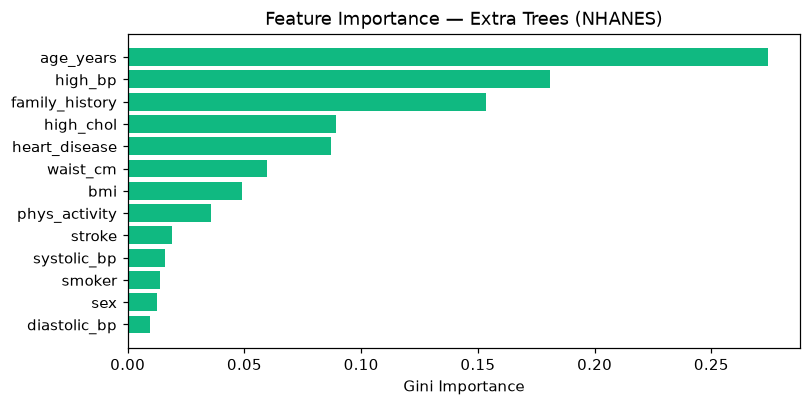

In [2]:
import matplotlib.pyplot as plt
import numpy as np

rf_step = et.named_steps["extratreesclassifier"]
importances = rf_step.feature_importances_
order = np.argsort(importances)

fig, ax = plt.subplots(figsize=(7.5, 3.8))
ax.barh([spec.features[i] for i in order], importances[order], color="#10b981")
ax.set_title("Feature Importance — Extra Trees (NHANES)")
ax.set_xlabel("Gini Importance")
plt.tight_layout()
